Dataset Shape: (525461, 8)

First 5 rows:
  Invoice StockCode                          Description  Quantity  \
0  489434     85048  15CM CHRISTMAS GLASS BALL 20 LIGHTS        12   
1  489434    79323P                   PINK CHERRY LIGHTS        12   
2  489434    79323W                  WHITE CHERRY LIGHTS        12   
3  489434     22041         RECORD FRAME 7" SINGLE SIZE         48   
4  489434     21232       STRAWBERRY CERAMIC TRINKET BOX        24   

          InvoiceDate  Price  Customer ID         Country  
0 2009-12-01 07:45:00   6.95      13085.0  United Kingdom  
1 2009-12-01 07:45:00   6.75      13085.0  United Kingdom  
2 2009-12-01 07:45:00   6.75      13085.0  United Kingdom  
3 2009-12-01 07:45:00   2.10      13085.0  United Kingdom  
4 2009-12-01 07:45:00   1.25      13085.0  United Kingdom  

CHECKING FOR MISSING DATA
Missing Values:
Invoice             0
StockCode           0
Description      2928
Quantity            0
InvoiceDate         0
Price               0
Cu

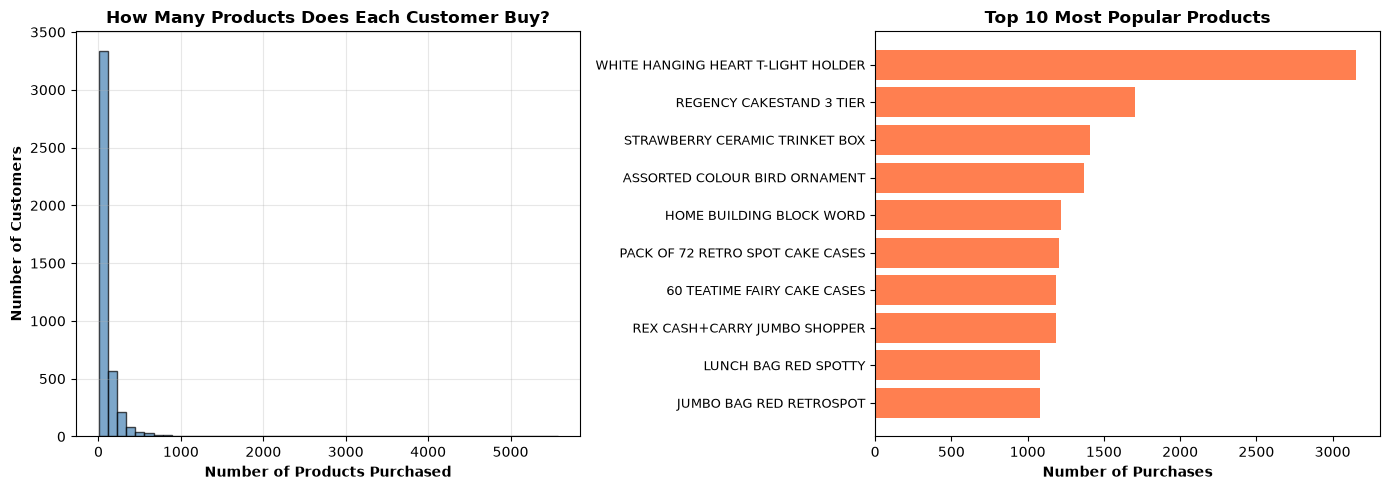


✅ Data exploration complete!


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['figure.figsize'] = (12, 6)


df = pd.read_excel('online_retail_II.xlsx')

# Display basic info
print("Dataset Shape:", df.shape)
print("\nFirst 5 rows:")
print(df.head())

print("\n" + "="*80)
print("CHECKING FOR MISSING DATA")
print("="*80)

# Check missing values
print("Missing Values:")
print(df.isnull().sum())

print("\n" + "="*80)
print("CLEANING THE DATA")
print("="*80)

# Remove rows with missing CustomerID
df_clean = df.dropna(subset=['Customer ID'])
print(f"Original dataset: {len(df)} rows")
print(f"After removing missing Customer ID: {len(df_clean)} rows")

# Remove negative quantities (returns/cancellations)
df_clean = df_clean[df_clean['Quantity'] > 0]

# Remove negative prices (data errors)
df_clean = df_clean[df_clean['Price'] > 0]
print(f"After removing negative quantities/prices: {len(df_clean)} rows")

print("\n✅ Cleaned dataset ready!")

print("\n" + "="*80)
print("UNDERSTANDING YOUR DATA")
print("="*80)

# How many unique customers and products?
num_customers = df_clean['Customer ID'].nunique()
num_products = df_clean['Description'].nunique()
num_transactions = len(df_clean)

print(f"\n📊 KEY STATISTICS:")
print(f"   Total Customers: {num_customers}")
print(f"   Total Products: {num_products}")
print(f"   Total Transactions: {num_transactions}")
print(f"   Average purchases per customer: {num_transactions / num_customers:.2f}")

# Which products are most popular?
print("\n✅ Top 10 Most Purchased Products:")
top_products = df_clean['Description'].value_counts().head(10)
for i, (product, count) in enumerate(top_products.items(), 1):
    print(f"   {i}. {product} → {count} purchases")

# Which products generate most revenue?
df_clean['Revenue'] = df_clean['Quantity'] * df_clean['Price']
print("\n💰 Top 5 Products by Revenue:")
top_revenue = df_clean.groupby('Description')['Revenue'].sum().sort_values(ascending=False).head(5)
for i, (product, revenue) in enumerate(top_revenue.items(), 1):
    print(f"   {i}. {product} → £{revenue:.2f}")

# How many products does average customer buy?
customer_purchases = df_clean.groupby('Customer ID')['Description'].count()
print(f"\n🛍️ Customer Purchase Patterns:")
print(f"   Average products per customer: {customer_purchases.mean():.2f}")
print(f"   Max products by one customer: {customer_purchases.max()}")
print(f"   Min products by a customer: {customer_purchases.min()}")

print("\n" + "="*80)
print("VISUALIZATIONS")
print("="*80)

# Plot 1 & 2
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Chart 1: Customer purchase distribution
axes[0].hist(customer_purchases, bins=50, edgecolor='black', alpha=0.7, color='steelblue')
axes[0].set_xlabel('Number of Products Purchased', fontweight='bold')
axes[0].set_ylabel('Number of Customers', fontweight='bold')
axes[0].set_title('How Many Products Does Each Customer Buy?', fontweight='bold')
axes[0].grid(True, alpha=0.3)

# Chart 2: Top 10 products
top_10_products = df_clean['Description'].value_counts().head(10)
axes[1].barh(range(10), top_10_products.values, color='coral')
axes[1].set_yticks(range(10))
axes[1].set_yticklabels([p[:35] for p in top_10_products.index], fontsize=9)
axes[1].set_xlabel('Number of Purchases', fontweight='bold')
axes[1].set_title('Top 10 Most Popular Products', fontweight='bold')
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

print("\n✅ Data exploration complete!")

In [5]:
# Step 3: Build User-Item Matrix

print("\n" + "="*80)
print("STEP 3: BUILDING USER-ITEM MATRIX")
print("="*80)

# Create the user-item matrix
# Rows = Customers, Columns = Products, Values = Quantity purchased
user_item_matrix = df_clean.pivot_table(
    index='Customer ID',           # Rows = Customers
    columns='Description',          # Columns = Products
    values='Quantity',              # Values = How many bought
    aggfunc='sum',                  # If same customer bought same product multiple times, sum them
    fill_value=0                    # Empty cells = 0 (didn't buy)
)

print(f"\n✅ User-Item Matrix Created!")
print(f"   Shape: {user_item_matrix.shape}")
print(f"   → {user_item_matrix.shape[0]} customers (rows)")
print(f"   → {user_item_matrix.shape[1]} products (columns)")

# Display first few rows and columns
print("\n📊 First 5 customers × First 8 products:")
print(user_item_matrix.iloc[:5, :8])

# Check sparsity (how many zeros vs actual purchases)
total_cells = user_item_matrix.shape[0] * user_item_matrix.shape[1]
filled_cells = (user_item_matrix > 0).sum().sum()
sparsity = (1 - filled_cells / total_cells) * 100

print(f"\n📈 Matrix Sparsity Analysis:")
print(f"   Total cells: {total_cells:,}")
print(f"   Filled cells (purchases): {filled_cells:,}")
print(f"   Empty cells (no purchase): {total_cells - filled_cells:,}")
print(f"   Sparsity: {sparsity:.2f}% (higher = more products customers haven't bought)")

# Summary statistics
print(f"\n📊 Purchase Statistics:")
print(f"   Average purchases per (customer, product) pair: {user_item_matrix.values.mean():.2f}")
print(f"   Max purchases of single product by one customer: {user_item_matrix.values.max():.0f}")
print(f"   Products with highest total purchases: {user_item_matrix.sum(axis=0).idxmax()}")
print(f"   Customer who bought most products: {user_item_matrix.sum(axis=1).idxmax()}")

# Save for later use
print("\n✅ Matrix saved for next steps!")


STEP 3: BUILDING USER-ITEM MATRIX

✅ User-Item Matrix Created!
   Shape: (4312, 4444)
   → 4312 customers (rows)
   → 4444 products (columns)

📊 First 5 customers × First 8 products:
Description   DOORMAT UNION JACK GUNS AND ROSES  3 STRIPEY MICE FELTCRAFT  \
Customer ID                                                                 
12346.0                                       0                         0   
12347.0                                       0                         0   
12348.0                                       0                         0   
12349.0                                       0                         0   
12351.0                                       0                         0   

Description  4 PURPLE FLOCK DINNER CANDLES  ANIMAL STICKERS  \
Customer ID                                                   
12346.0                                  0                0   
12347.0                                  0                0   
12348.0                 

In [7]:
# Step 4: Calculate Cosine Similarity Between Customers

print("\n" + "="*80)
print("STEP 4: CALCULATING CUSTOMER SIMILARITY")
print("="*80)

from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

print("\n🔄 Calculating cosine similarity between all customers...")
print("   (This measures: how similar is Customer A to Customer B?)")

# Calculate similarity matrix
# cosine_similarity returns a matrix where:
# - Row i, Column j = similarity between Customer i and Customer j
similarity_matrix = cosine_similarity(user_item_matrix)

print(f"\n✅ Similarity Matrix Calculated!")
print(f"   Shape: {similarity_matrix.shape}")
print(f"   → {similarity_matrix.shape[0]} × {similarity_matrix.shape[1]} matrix")

# Convert to DataFrame for easier understanding
similarity_df = pd.DataFrame(
    similarity_matrix,
    index=user_item_matrix.index,
    columns=user_item_matrix.index
)

print(f"\n📊 Example: Similarity Scores for First 5 Customers")
print(f"   (Numbers closer to 1.0 = more similar)")
print(similarity_df.iloc[:5, :5].round(3))

# Key insights
print("\n" + "="*80)
print("KEY INSIGHTS FROM SIMILARITY MATRIX")
print("="*80)

# 1. Diagonal should be 1.0 (a customer is 100% similar to themselves)
diagonal_values = np.diag(similarity_matrix)
print(f"\n✅ Diagonal values (should be 1.0):")
print(f"   Min: {diagonal_values.min():.4f}")
print(f"   Max: {diagonal_values.max():.4f}")
print(f"   Mean: {diagonal_values.mean():.4f}")

# 2. Find most similar customer pairs (excluding self-similarity)
print(f"\n🔍 Most Similar Customer Pairs (Top 10):")
print(f"   (Similarity ≠ 1.0, so not comparing with themselves)")

# Get all similarity scores (excluding diagonal)
similarities_list = []
for i in range(len(similarity_df)):
    for j in range(i+1, len(similarity_df)):
        customer_i = similarity_df.index[i]
        customer_j = similarity_df.index[j]
        similarity_score = similarity_df.iloc[i, j]
        similarities_list.append({
            'Customer_A': customer_i,
            'Customer_B': customer_j,
            'Similarity': similarity_score
        })

# Convert to DataFrame and sort
similarity_pairs = pd.DataFrame(similarities_list)
top_similar_pairs = similarity_pairs.nlargest(10, 'Similarity')

for idx, row in top_similar_pairs.iterrows():
    print(f"   {idx+1}. Customer {row['Customer_A']:.0f} ↔ {row['Customer_B']:.0f}: {row['Similarity']:.4f}")

# 3. Distribution of similarities
print(f"\n📈 Similarity Score Distribution:")
all_similarities = similarity_matrix[np.triu_indices_from(similarity_matrix, k=1)]
print(f"   Min similarity: {all_similarities.min():.4f}")
print(f"   Max similarity: {all_similarities.max():.4f}")
print(f"   Mean similarity: {all_similarities.mean():.4f}")
print(f"   Median similarity: {np.median(all_similarities):.4f}")

# 4. How many "similar" pairs (similarity > 0.5)?
similar_count = (all_similarities > 0.5).sum()
print(f"\n✅ Pairs with high similarity (> 0.5): {similar_count:,} out of {len(all_similarities):,}")
print(f"   Percentage: {(similar_count / len(all_similarities)) * 100:.2f}%")

# 5. Find most similar customers to a specific customer
print(f"\n" + "="*80)
print("EXAMPLE: FIND SIMILAR CUSTOMERS")
print("="*80)

# Pick first customer as example
example_customer = user_item_matrix.index[0]
print(f"\n👤 Example Customer: {example_customer:.0f}")

# Get their similarity scores
similarities_to_example = similarity_df.loc[example_customer].sort_values(ascending=False)

print(f"\n   Top 5 most similar customers to Customer {example_customer:.0f}:")
for i, (customer, similarity) in enumerate(similarities_to_example.head(5).items(), 1):
    print(f"   {i}. Customer {customer:.0f}: {similarity:.4f}")

print("\n✅ Similarity matrix ready for recommendations!")


STEP 4: CALCULATING CUSTOMER SIMILARITY

🔄 Calculating cosine similarity between all customers...
   (This measures: how similar is Customer A to Customer B?)

✅ Similarity Matrix Calculated!
   Shape: (4312, 4312)
   → 4312 × 4312 matrix

📊 Example: Similarity Scores for First 5 Customers
   (Numbers closer to 1.0 = more similar)
Customer ID  12346.0  12347.0  12348.0  12349.0  12351.0
Customer ID                                             
12346.0        1.000    0.000     0.00    0.003    0.000
12347.0        0.000    1.000     0.11    0.009    0.154
12348.0        0.000    0.110     1.00    0.000    0.000
12349.0        0.003    0.009     0.00    1.000    0.010
12351.0        0.000    0.154     0.00    0.010    1.000

KEY INSIGHTS FROM SIMILARITY MATRIX

✅ Diagonal values (should be 1.0):
   Min: 1.0000
   Max: 1.0000
   Mean: 1.0000

🔍 Most Similar Customer Pairs (Top 10):
   (Similarity ≠ 1.0, so not comparing with themselves)
   60428. Customer 12362 ↔ 12636: 1.0000
   175972.

In [8]:
# Step 5: Collaborative Filtering Recommendations

def get_recommendations(customer_id, n_recommendations=5, n_similar_customers=10):
    if customer_id not in similarity_df.index:
        print(f"Customer {customer_id} not found.")
        return None

    # 1. Find the most similar customers (excluding the customer themselves)
    sims = similarity_df.loc[customer_id].drop(customer_id).sort_values(ascending=False)
    similar_customers = sims.head(n_similar_customers)

    # 2. Products this customer already bought
    owned = set(user_item_matrix.columns[user_item_matrix.loc[customer_id] > 0])

    # 3. Score products bought by similar customers
    scores = {}
    for sim_cust, sim_score in similar_customers.items():
        row = user_item_matrix.loc[sim_cust]
        for product in row[row > 0].index:
            if product not in owned:
                scores[product] = scores.get(product, 0) + sim_score * row[product]

    if not scores:
        print("No recommendations found for this customer.")
        return None

    # 4. Return top-N as a table
    recs = (pd.Series(scores, name="Score")
              .sort_values(ascending=False)
              .head(n_recommendations)
              .rename_axis("Product")
              .reset_index())
    recs.insert(0, "Rank", range(1, len(recs) + 1))
    return recs


# Test on a few customers
test_customers = user_item_matrix.index[:3]


for cust in test_customers:
    print(f"\n=== Recommendations for Customer {int(cust)} ===")
    recs = get_recommendations(cust, n_recommendations=5, n_similar_customers=10)
    if recs is not None:
        print(recs.to_string(index=False))


=== Recommendations for Customer 12346 ===
 Rank                           Product    Score
    1               BLUE PAPER PARASOL  3.370748
    2  BLACK/BLUE DOTS RUFFLED UMBRELLA 2.541417
    3 ASSORTED ICE CREAM FRIDGE MAGNETS 1.989250
    4    ASSORTED CHEESE FRIDGE MAGNETS 1.989250
    5              PURPLE PAPER PARASOL 1.802517

=== Recommendations for Customer 12347 ===
 Rank                            Product      Score
    1   PACK OF 72 RETRO SPOT CAKE CASES 157.094526
    2          JAPANESE CROCHETED ANIMAL 128.739670
    3         MAGIC DRAWING SLATE PURDEY 110.380031
    4        FELT EGG COSY WHITE RABBIT   96.582527
    5 PACK OF 60 PINK PAISLEY CAKE CASES  86.789978

=== Recommendations for Customer 12348 ===
 Rank                          Product       Score
    1 PACK OF 12 PINK PAISLEY TISSUES  7332.176911
    2    PACK OF 12 PINK SPOT TISSUES  1856.568706
    3 PACK OF 72 RETRO SPOT CAKE CASES 1739.134782
    4   PACK OF 60 DINOSAUR CAKE CASES 1661.450125
    5  